In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

con = duckdb.connect("../data/processed/flights.duckdb")
df = con.execute("SELECT * FROM features").df()
con.close()

CUTOFF = pd.Timestamp("2025-05-01")          # match your Step 3 cutoff
df["flight_date"] = pd.to_datetime(df["flight_date"])

cat_cols = ["carrier", "Origin", "Dest"]
for c in cat_cols:
    df[c] = df[c].astype("category")

drop = ["target", "arr_delay_min", "flight_date", "tail"]
feat_cols = [c for c in df.columns if c not in drop]

train = df[df["flight_date"] <  CUTOFF]
test  = df[df["flight_date"] >= CUTOFF]
X_tr, y_tr = train[feat_cols], train["target"]
X_te, y_te = test[feat_cols],  test["target"]

print(f"Train {len(train):,}  ({train['flight_date'].min().date()} to {train['flight_date'].max().date()})")
print(f"Test  {len(test):,}  ({test['flight_date'].min().date()} to {test['flight_date'].max().date()})")
print(f"Delay rate — train {y_tr.mean():.1%}, test {y_te.mean():.1%}")

Train 2,188,776  (2025-01-01 to 2025-04-30)
Test  1,197,046  (2025-05-01 to 2025-06-30)
Delay rate — train 19.7%, test 25.9%


In [2]:
results = []

# Baseline 1: predict the training base rate for everyone
p_base = np.full(len(y_te), y_tr.mean())
results.append({"model": "Baseline: base rate",
                "ROC-AUC": 0.5,
                "PR-AUC": average_precision_score(y_te, p_base),
                "Brier": brier_score_loss(y_te, p_base)})

# Baseline 2: use the route's historical delay rate as the prediction
p_route = X_te["route_delay_rate"].values
results.append({"model": "Baseline: route history",
                "ROC-AUC": roc_auc_score(y_te, p_route),
                "PR-AUC": average_precision_score(y_te, p_route),
                "Brier": brier_score_loss(y_te, p_route)})

print(pd.DataFrame(results).round(4).to_string(index=False))

                  model  ROC-AUC  PR-AUC  Brier
    Baseline: base rate   0.5000  0.2593 0.1960
Baseline: route history   0.5757  0.3086 0.1935


In [3]:
num_cols = [c for c in feat_cols if c not in cat_cols]
med = X_tr[num_cols].median()
Xn_tr = X_tr[num_cols].fillna(med)
Xn_te = X_te[num_cols].fillna(med)

sc = StandardScaler().fit(Xn_tr)
lr = LogisticRegression(max_iter=1000).fit(sc.transform(Xn_tr), y_tr)
p_lr = lr.predict_proba(sc.transform(Xn_te))[:, 1]

results.append({"model": "Logistic regression",
                "ROC-AUC": roc_auc_score(y_te, p_lr),
                "PR-AUC": average_precision_score(y_te, p_lr),
                "Brier": brier_score_loss(y_te, p_lr)})
print(pd.DataFrame(results).round(4).to_string(index=False))

                  model  ROC-AUC  PR-AUC  Brier
    Baseline: base rate   0.5000  0.2593 0.1960
Baseline: route history   0.5757  0.3086 0.1935
    Logistic regression   0.7625  0.5991 0.1535


In [4]:
model = lgb.LGBMClassifier(
    n_estimators=800, learning_rate=0.05, num_leaves=63,
    min_child_samples=100, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, n_jobs=-1, verbose=-1)
model.fit(X_tr, y_tr, categorical_feature=cat_cols)
p_gbm = model.predict_proba(X_te)[:, 1]

results.append({"model": "LightGBM",
                "ROC-AUC": roc_auc_score(y_te, p_gbm),
                "PR-AUC": average_precision_score(y_te, p_gbm),
                "Brier": brier_score_loss(y_te, p_gbm)})

res_df = pd.DataFrame(results).round(4)
print(res_df.to_string(index=False))
res_df.to_csv("../results/model_comparison.csv", index=False)

                  model  ROC-AUC  PR-AUC  Brier
    Baseline: base rate   0.5000  0.2593 0.1960
Baseline: route history   0.5757  0.3086 0.1935
    Logistic regression   0.7625  0.5991 0.1535
               LightGBM   0.8163  0.7250 0.1252


In [5]:
prop_feats = ["prev_arr_delay", "is_first_leg", "leg_number", "turnaround_min"]
no_prop = [c for c in feat_cols if c not in prop_feats]

m2 = lgb.LGBMClassifier(
    n_estimators=800, learning_rate=0.05, num_leaves=63,
    min_child_samples=100, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, n_jobs=-1, verbose=-1)
m2.fit(X_tr[no_prop], y_tr, categorical_feature=cat_cols)
p_nop = m2.predict_proba(X_te[no_prop])[:, 1]

auc_full = roc_auc_score(y_te, p_gbm)
auc_nop  = roc_auc_score(y_te, p_nop)
print(f"With propagation:    ROC-AUC {auc_full:.4f}  PR-AUC {average_precision_score(y_te, p_gbm):.4f}")
print(f"Without propagation: ROC-AUC {auc_nop:.4f}  PR-AUC {average_precision_score(y_te, p_nop):.4f}")
print(f"Improvement: {auc_full - auc_nop:+.4f}")

With propagation:    ROC-AUC 0.8163  PR-AUC 0.7250
Without propagation: ROC-AUC 0.6699  PR-AUC 0.3888
Improvement: +0.1463


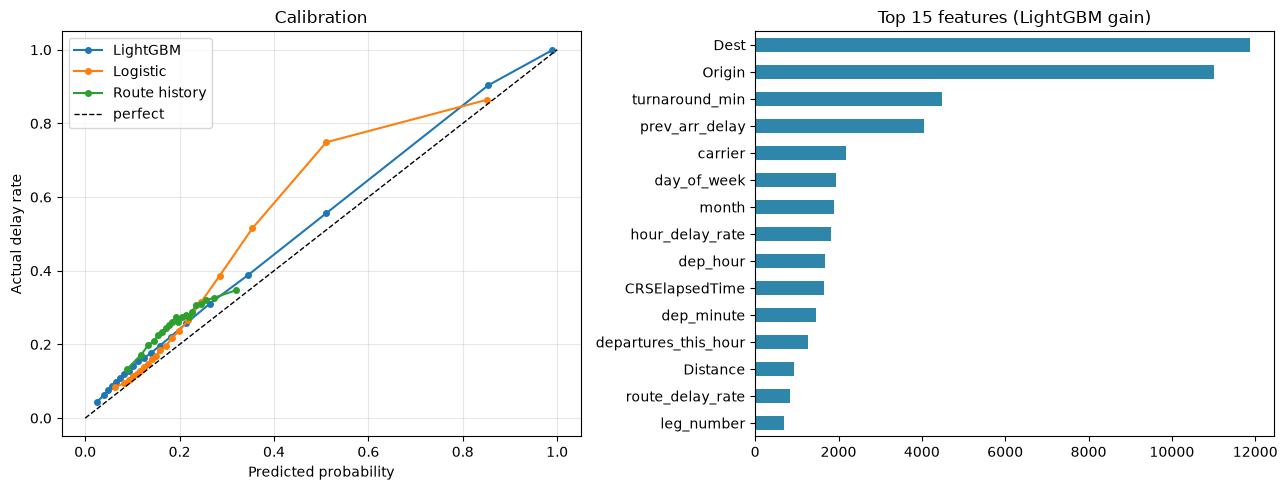

Dest               11864
Origin             11007
turnaround_min      4482
prev_arr_delay      4041
carrier             2178
day_of_week         1941
month               1886
hour_delay_rate     1818
dep_hour            1679
CRSElapsedTime      1661


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for name, p in [("LightGBM", p_gbm), ("Logistic", p_lr), ("Route history", p_route)]:
    frac, mean_pred = calibration_curve(y_te, p, n_bins=20, strategy="quantile")
    ax[0].plot(mean_pred, frac, marker="o", ms=4, label=name)
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
ax[0].set_xlabel("Predicted probability"); ax[0].set_ylabel("Actual delay rate")
ax[0].set_title("Calibration"); ax[0].legend(); ax[0].grid(alpha=.3)

imp = pd.Series(model.feature_importances_, index=feat_cols).sort_values()[-15:]
imp.plot.barh(ax=ax[1], color="#2e86ab")
ax[1].set_title("Top 15 features (LightGBM gain)")

plt.tight_layout()
plt.savefig("../figures/02_calibration_importance.png", dpi=200)
plt.show()

print(pd.Series(model.feature_importances_, index=feat_cols)
      .sort_values(ascending=False).head(10).to_string())

In [7]:
test_eval = test[["flight_date", "carrier", "Origin", "dep_hour", "is_first_leg"]].copy()
test_eval["y"] = y_te.values
test_eval["p"] = p_gbm

print("By first-leg status:")
print(test_eval.groupby("is_first_leg").apply(
    lambda g: pd.Series({"n": len(g), "actual_rate": g["y"].mean(),
                         "ROC-AUC": roc_auc_score(g["y"], g["p"])}),
    include_groups=False).round(4).to_string())

By first-leg status:
                     n  actual_rate  ROC-AUC
is_first_leg                                
0             904691.0       0.2955   0.8385
1             292355.0       0.1475   0.6779


In [8]:
import pickle
with open("../results/model.pkl", "wb") as f:
    pickle.dump({"model": model, "feat_cols": feat_cols, "cat_cols": cat_cols}, f)

np.save("../results/test_preds.npy", p_gbm)
test[["flight_date", "carrier", "Origin", "Dest", "dep_hour", "is_first_leg", "target"]].to_csv(
    "../results/test_meta.csv", index=False)
print("Saved")

Saved


In [9]:
print(f"Mean predicted probability: {p_gbm.mean():.4f}")
print(f"Actual delay rate:          {y_te.mean():.4f}")

Mean predicted probability: 0.2240
Actual delay rate:          0.2593


In [10]:
imp_gain = pd.Series(model.booster_.feature_importance(importance_type="gain"),
                     index=feat_cols).sort_values(ascending=False)
print(imp_gain.head(10).to_string())

prev_arr_delay      3.289904e+06
turnaround_min      9.081494e+05
Dest                4.175505e+05
Origin              3.878609e+05
hour_delay_rate     2.336744e+05
is_first_leg        2.231484e+05
route_delay_rate    1.852301e+05
carrier             1.113148e+05
leg_number          9.969848e+04
dep_hour            9.645844e+04


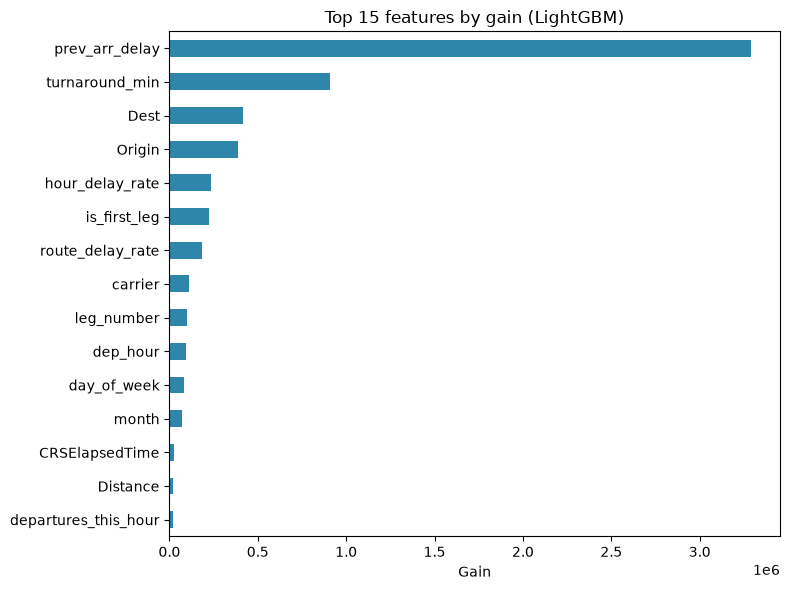

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
imp_gain.head(15).sort_values().plot.barh(ax=ax, color="#2e86ab")
ax.set_xlabel("Gain")
ax.set_title("Top 15 features by gain (LightGBM)")
plt.tight_layout()
plt.savefig("../figures/03_feature_importance_gain.png", dpi=200)
plt.show()

In [12]:
from sklearn.isotonic import IsotonicRegression

# Use the first 2 weeks of the test period to calibrate, evaluate on the rest
cal_mask = test["flight_date"] < pd.Timestamp("2025-05-15")
iso = IsotonicRegression(out_of_bounds="clip").fit(p_gbm[cal_mask.values], y_te[cal_mask.values])
p_cal = iso.predict(p_gbm)

print("Before calibration:")
print(f"  Brier {brier_score_loss(y_te[~cal_mask.values], p_gbm[~cal_mask.values]):.4f}, "
      f"mean pred {p_gbm[~cal_mask.values].mean():.4f}")
print("After calibration:")
print(f"  Brier {brier_score_loss(y_te[~cal_mask.values], p_cal[~cal_mask.values]):.4f}, "
      f"mean pred {p_cal[~cal_mask.values].mean():.4f}")
print(f"Actual rate: {y_te[~cal_mask.values].mean():.4f}")
print(f"ROC-AUC unchanged: {roc_auc_score(y_te[~cal_mask.values], p_cal[~cal_mask.values]):.4f}")

Before calibration:
  Brier 0.1266, mean pred 0.2281
After calibration:
  Brier 0.1254, mean pred 0.2522
Actual rate: 0.2667
ROC-AUC unchanged: 0.8190


In [13]:
np.save("../results/test_preds_calibrated.npy", p_cal)
import pickle
with open("../results/calibrator.pkl", "wb") as f:
    pickle.dump(iso, f)